# 03 — Prévision de la volatilité par LSTM (S4)

**Objectif** : prévoir la volatilité qui servira d'entrée `σ` au pricer, et vérifier honnêtement si un LSTM fait mieux que des méthodes simples.

| Variante | Entrée | Cible |
|---|---|---|
| **V0 (guide)** | 30 dernières volatilités réalisées sur 5 jours | volatilité réalisée du lendemain |
| **V1 (rigoureuse)** | 30 derniers rendements journaliers | volatilité réalisée annualisée des **5 jours suivants** |

V0 est biaisée en faveur de la persistance : la cible du lendemain partage 4 rendements sur 5 avec la dernière entrée. V1 n'a aucun chevauchement entre entrée et cible.

**Méthode** : découpage chronologique 70 / 15 / 15 (jamais aléatoire), normalisation apprise sur le train seul, `LSTM(32)` puis `Dense(1)`, arrêt anticipé sur la validation. **Références** sur le même jeu de test : persistance, EWMA (λ = 0,94), GARCH(1,1). **Métriques** : RMSE (en points de volatilité) et QLIKE (sur les variances, 0 = parfait).

In [1]:
import sys, os
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
from arch import arch_model
from data import load_prices_info, log_returns
from ml import (FENETRE, HORIZON, make_dataset_v0, make_dataset_v1, chrono_split, fit_minmax, scale, unscale,
                persistence_v1, ewma_v1, garch_v1, rmse, qlike, lstm_forward, save_model, predict_vol)
tf.keras.utils.set_random_seed(42)
os.makedirs("../docs/figures", exist_ok=True); os.makedirs("../models", exist_ok=True)

I0000 00:00:1794423669.748537     716 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794423670.695711     716 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Données : 10 ans de rendements journaliers d'AAPL
Ordre : yfinance, CSV de repli `data/aapl_10y_fallback.csv`, sinon simulation GARCH(1,1) **étiquetée comme telle** (elle reproduit le regroupement de la volatilité, mais ce ne sont pas des données de marché).

In [2]:
try:
    prices, SOURCE = load_prices_info("AAPL", "10y", csv_fallback="../data/aapl_10y_fallback.csv")
    r = log_returns(prices)
except (RuntimeError, FileNotFoundError):
    rng, n, w, a, b = np.random.default_rng(42), 2520, 2e-6, 0.08, 0.90
    s2, x = w / (1 - a - b), []
    for _ in range(n):
        e = np.sqrt(s2) * rng.standard_normal(); x.append(e); s2 = w + a * e * e + b * s2
    r = pd.Series(x, index=pd.bdate_range(end=pd.Timestamp.today().normalize(), periods=n))
    SOURCE = "simulation GARCH(1,1) (données NON réelles)"
print("SOURCE =", SOURCE, "|", len(r), "rendements")

SOURCE = simulation GARCH(1,1) (données NON réelles) | 2520 rendements


## 2. Jeux de données, découpage chronologique, normalisation

In [3]:
data = {}
for nom, (X, y) in {"V0": make_dataset_v0(r), "V1": make_dataset_v1(r)}.items():
    a, b = chrono_split(len(y))
    xs = fit_minmax(X[:a]); ys = xs if nom == "V0" else fit_minmax(y[:a])   # appris sur le train seul
    data[nom] = dict(X=X, y=y, a=a, b=b, xs=xs, ys=ys)
    print(f"{nom} : {len(y)} séquences → train {a}, validation {b - a}, test {len(y) - b}")

V0 : 2486 séquences → train 1740, validation 373, test 373
V1 : 2486 séquences → train 1740, validation 373, test 373


## 3. Entraînement

V0 époques : 100


V1 époques : 85


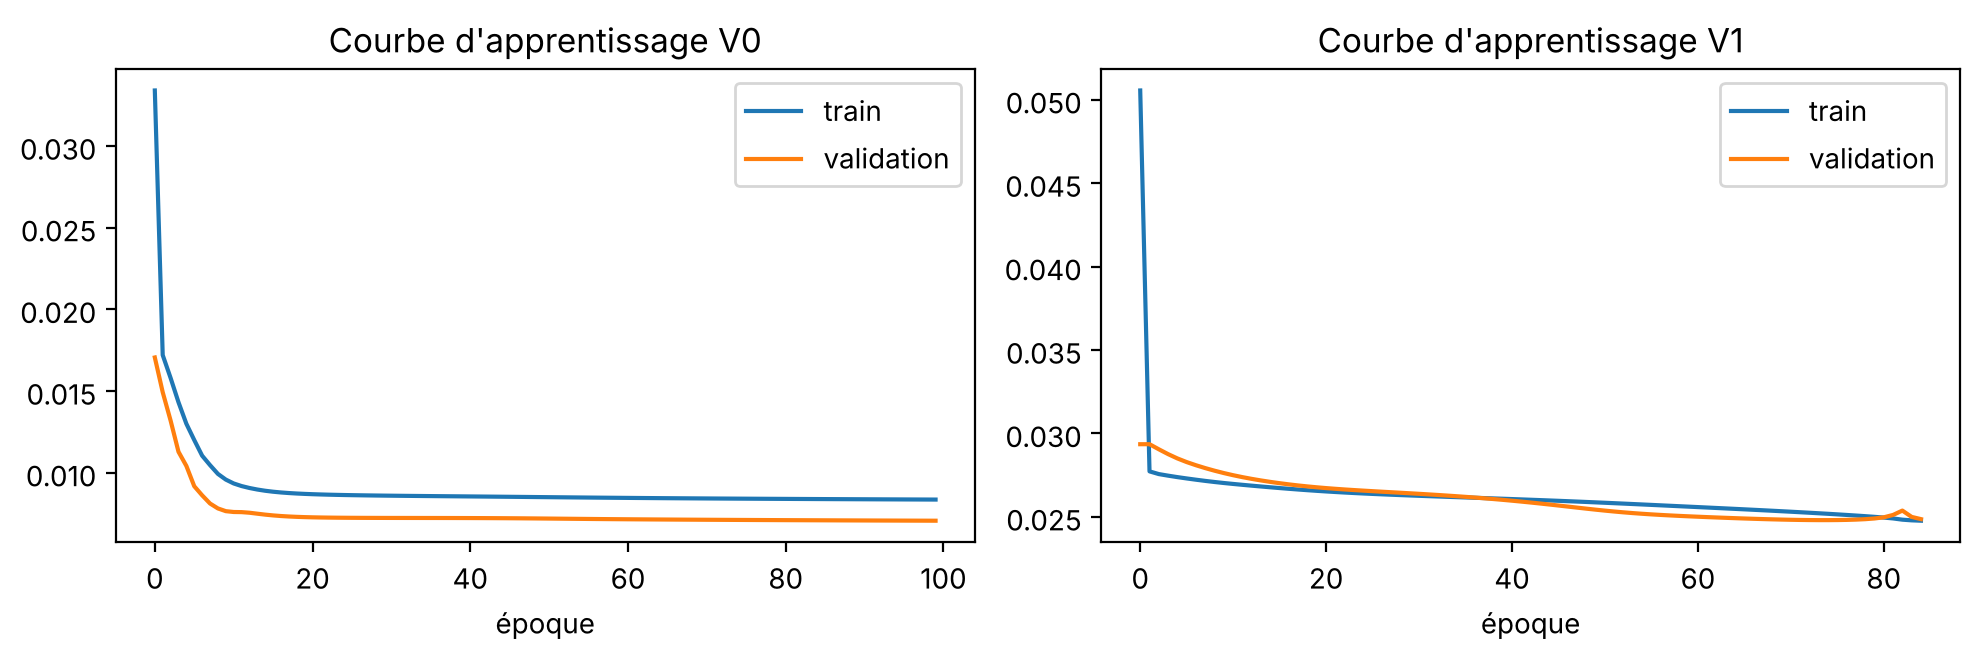

In [4]:
def entrainer(d):
    Xs, ys = scale(d["X"], *d["xs"]), scale(d["y"], *d["ys"])
    m = tf.keras.Sequential([tf.keras.Input((FENETRE, 1)), tf.keras.layers.LSTM(32), tf.keras.layers.Dense(1)])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
    h = m.fit(Xs[:d["a"]], ys[:d["a"]], validation_data=(Xs[d["a"]:d["b"]], ys[d["a"]:d["b"]]), epochs=100, batch_size=32,
              callbacks=[tf.keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)], verbose=0)
    d["pred"] = unscale(m.predict(Xs[d["b"]:], verbose=0).ravel(), *d["ys"])
    return m, h
modeles, historiques = {}, {}
for nom in data:
    modeles[nom], historiques[nom] = entrainer(data[nom])
    print(nom, "époques :", len(historiques[nom].history["loss"]))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for i, nom in enumerate(data):
    ax[i].plot(historiques[nom].history["loss"], label="train"); ax[i].plot(historiques[nom].history["val_loss"], label="validation")
    ax[i].set_title(f"Courbe d'apprentissage {nom}"); ax[i].set_xlabel("époque"); ax[i].legend()
fig.tight_layout(); fig.savefig("../docs/figures/fig_05_apprentissage_lstm.png", dpi=150); plt.show()

## 4. Références sur le même jeu de test
GARCH(1,1) est estimé sur les rendements de la période d'entraînement seulement (bibliothèque `arch`), puis appliqué à chaque fenêtre de test.

In [5]:
d0, d1 = data["V0"], data["V1"]
Xt1, yt1 = d1["X"][d1["b"]:], d1["y"][d1["b"]:]
g = arch_model(100 * r.iloc[:int(len(r) * 0.70)], vol="GARCH", p=1, q=1, mean="Zero").fit(disp="off").params
omega, alpha, beta = g["omega"] / 1e4, g["alpha[1]"], g["beta[1]"]
print(f"GARCH(1,1) estimé sur le train : ω = {omega:.2e}, α = {alpha:.3f}, β = {beta:.3f}")
lignes = [("V0", "LSTM", d0["y"][d0["b"]:], d0["pred"]),
          ("V0", "Persistance", d0["y"][d0["b"]:], d0["X"][d0["b"]:, -1, 0]),
          ("V1", "LSTM", yt1, d1["pred"]),
          ("V1", "Persistance", yt1, persistence_v1(Xt1)),
          ("V1", "EWMA λ = 0,94", yt1, ewma_v1(Xt1)),
          ("V1", "GARCH(1,1)", yt1, garch_v1(Xt1, omega, alpha, beta))]
res = pd.DataFrame([{"variante": v, "modèle": m, "RMSE": rmse(y, p), "QLIKE": qlike(y, p)} for v, m, y, p in lignes])
res.to_csv("../docs/figures/resultats_ia.csv", index=False)
print("SOURCE =", SOURCE); print(res.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

GARCH(1,1) estimé sur le train : ω = 1.61e-06, α = 0.064, β = 0.920
SOURCE = simulation GARCH(1,1) (données NON réelles)
variante        modèle   RMSE  QLIKE
      V0          LSTM 0.0452 0.1904
      V0   Persistance 0.0471 0.2483
      V1          LSTM 0.0880 0.7566
      V1   Persistance 0.0884 1.0038
      V1 EWMA λ = 0,94 0.0710 0.3574
      V1    GARCH(1,1) 0.0689 0.3398


## 5. Prévisions contre réalisé (V1, jeu de test)

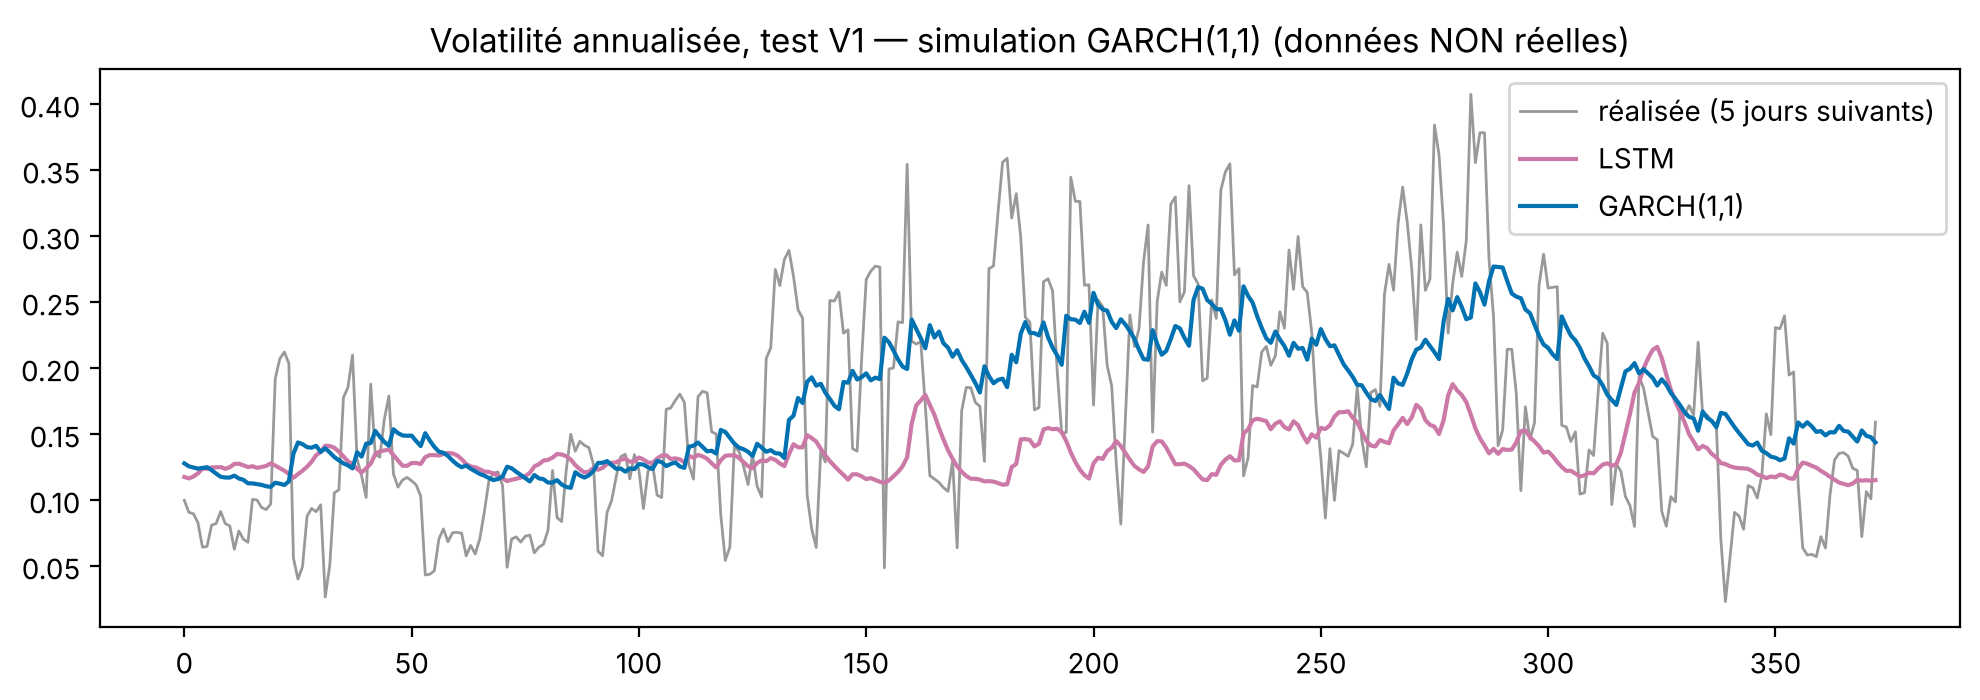

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(yt1, color="#999999", lw=1, label="réalisée (5 jours suivants)")
ax.plot(d1["pred"], color="#CC79A7", label="LSTM"); ax.plot(garch_v1(Xt1, omega, alpha, beta), color="#0072B2", label="GARCH(1,1)")
ax.set_title(f"Volatilité annualisée, test V1 — {SOURCE}"); ax.legend(); fig.tight_layout()
fig.savefig("../docs/figures/fig_06_previsions_v1.png", dpi=150); plt.show()

## 6. Lecture des résultats
Le meilleur modèle est celui dont la RMSE et la QLIKE sont les plus faibles **sur le test**. Si une référence simple (persistance, EWMA, GARCH) bat le LSTM, c'est un résultat à présenter tel quel : il dit que la volatilité est déjà bien décrite par sa propre dynamique récente. Le tableau ci-dessus se relit après chaque exécution sur données réelles ; ne jamais recopier un chiffre de mémoire.

## 7. Export du modèle V1 pour Odoo
Odoo n'embarque pas TensorFlow : on exporte les poids dans `models/lstm_vol.npz` ; `src/ml.py` refait le calcul du LSTM en NumPy. La cellule vérifie que les deux calculs donnent le même résultat.

In [7]:
m = modeles["V1"]
W, U, b = m.layers[0].get_weights(); Wd, bd = m.layers[1].get_weights()
meta = {"variante": "V1", "window": FENETRE, "horizon": HORIZON, "x_scale": list(d1["xs"]), "y_scale": list(d1["ys"]),
        "source": SOURCE, "date": str(pd.Timestamp.today().date())}
save_model("../models/lstm_vol.npz", dict(W=W, U=U, b=b, Wd=Wd, bd=bd), meta)
derniere = predict_vol(r.to_numpy(), "../models/lstm_vol.npz")
keras = float(unscale(m.predict(scale(r.to_numpy()[-FENETRE:], *d1["xs"])[None, :, None], verbose=0).ravel(), *d1["ys"])[0])
print(f"prévision NumPy {derniere:.6f} | Keras {keras:.6f}"); assert abs(derniere - keras) < 1e-4
print(f"volatilité prévue pour les {HORIZON} prochains jours : {derniere:.1%}")

prévision NumPy 0.122552 | Keras 0.122552
volatilité prévue pour les 5 prochains jours : 12.3%
